# Classes, errors and tests

After this block you can design a class for a data task, choose between composition, inheritance and a dataclass, write down a function's contract with type hints and a docstring, raise and handle exceptions on purpose, and check your code with automated tests in pytest. The running example is one Berlin Airbnb listing from the course case study: a class that checks its own values once, when it is created, protects every piece of code that uses it.

*Session 2, block 1 of 2. Course material, CC BY 4.0; sections adapted from third-party material say so in an attribution line.*

## Overview

| Section | What it covers |
|---|---|
| Classes and objects | class and object, attributes, methods, `__init__` and `self`, designing with classes, `__str__` and `__repr__`, class attributes, class and static methods, properties, private names, comparing and sorting, identity and copies, pure functions and modifiers |
| Composition, inheritance and dataclasses | inheritance and overriding, `super()`, dataclasses and their options, composition, aggregation in UML, polymorphism, duck typing, choosing a type for a record |
| Type hints and docstrings | a function's written contract, hints are not checked at run time, the hint vocabulary, type checkers, docstring styles, doctest, comments |
| Exceptions and error handling | the exception hierarchy, own exception classes, `raise`, `try`/`except`/`else`/`finally` and `with`, chaining and re-raising, the call stack, EAFP and LBYL |
| Automated tests with pytest | why test, test files, `assert`, fixtures, `parametrize`, `pytest.raises`, a failing test, equivalence classes and boundaries, comparing floats, `tmp_path` and markers, test-driven development |
| Worked example | `ListingRecord` checks every Berlin listing; `NaN` against `None` |
| Check your understanding, Exercises, Debrief | five questions, ten exercises in pairs, what to compare afterwards |

The first code cell moves Python to the repository root, so that the path of the case-study data works on every computer.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

The block uses the Berlin listings of Session 1 (`airbnb-v1.zip` from the course drive, unzipped into `case-study/data/`; see [case-study/README.md](../../../case-study/README.md)). `pd.read_parquet` reads the file into a DataFrame; `priced` keeps the rows that have a price, because the first examples divide by it.

In [2]:
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
priced = listings.dropna(subset=["price"])
print(len(listings), "listings,", len(priced), "with a price")
priced[["id", "name", "district", "room_type", "accommodates", "price"]].head(3)

10221 listings, 6754 with a price


,id,name,district,room_type,accommodates,price
0,3176,Fabulous Flat in great Location,Pankow,Entire home/apt,2,160.71
1,9991,Geourgeous flat - outstanding views,Pankow,Entire home/apt,7,193.33
3,17904,Beautiful Kreuzberg studio - 3 months minimum,Friedrichshain-Kreuzberg,Entire home/apt,2,10.88


## Classes and objects

A **class** is a user-defined type, a blueprint for a kind of thing such as "a listing". An **object** (or **instance**) is one concrete thing built from that blueprint: the flat with id 3176 in Pankow. In the jargon, an object *is an instance of* a class. Think of a class as a printed form and of each object as one filled-in copy: the same boxes, different contents.

A class is worth writing when several functions work on the same data. The data and the rules that belong to it then live in one place.

### Attributes, methods and the constructor

A class bundles data and behaviour. The official Python terms are these:

- **Attributes** (also called member variables) are the data of an object, read with a dot: `flat.price`.
- **Methods** are functions defined inside the class; they say what the objects can do: `flat.price_per_guest()`.
- The **constructor** `__init__` is the method Python calls when you create an object with `Listing(...)`; it turns input data into attributes.
- `self` is the first parameter of every method: the object the method is called on, the thing "before the dot". `self` is a convention, not a keyword, but always use it.

Names that begin and end with two underscores, such as `__init__`, are **special methods** ("dunder" methods): Python calls them for you in particular situations.

```mermaid
classDiagram
  class Listing {
    +int id
    +str district
    +float price
    +int guests
    +price_per_guest() float
  }
```

The diagram is a **UML class diagram**: the class name on top, the attributes in the middle, the methods at the bottom.

Next we define the class `Listing`. `class Listing:` starts the definition; `__init__` stores four values on `self`; `price_per_guest` is a method; `__repr__` decides how an object is shown when printed.

In [3]:
class Listing:
    """One accommodation listing."""

    def __init__(self, id, district, price, guests):
        self.id = id                  # attributes: stored on this one object
        self.district = district
        self.price = price
        self.guests = guests

    def price_per_guest(self):        # a method: self is the object it is called on
        return round(self.price / self.guests, 2)

    def __repr__(self):
        return f"Listing({self.id}, {self.district!r}, {self.price})"

Now we create two objects from two real rows. `priced.iloc[i]` returns row `i` as a Series, whose values we can read with a dot (`row.price`). Calling the class like a function, `Listing(...)`, creates an object.

In [4]:
first, second = priced.iloc[0], priced.iloc[1]
flat = Listing(first.id, first.district, first.price, first.accommodates)
other = Listing(second.id, second.district, second.price, second.accommodates)
print(flat)
print(other)
print(flat.price_per_guest())

Listing(3176, 'Pankow', 160.71)
Listing(9991, 'Pankow', 193.33)
80.36


A method *is* a function: `flat.price_per_guest()` is short for `Listing.price_per_guest(flat)`, and Python passes `flat` as `self`. You have used methods since Session 1: `"pankow".title()` is the same call as `str.title("pankow")`. `type()` and `isinstance()` tell us the class of an object.

In [5]:
print(Listing.price_per_guest(flat))     # the same call, written as a function
print("pankow".title(), str.title("pankow"))
print(type(flat), isinstance(flat, Listing))

80.36
Pankow Pankow
<class '__main__.Listing'> True


### Each object owns its data

**Predict before running.** We raise the price of `flat` by 10 euros. Does `other` change too?

In [6]:
flat.price = flat.price + 10
print(flat)
print(other)

Listing(3176, 'Pankow', 170.71)
Listing(9991, 'Pankow', 193.33)


Each object owns its attributes, so `other` is unchanged. This is the point of objects: many listings, one set of rules.

### Designing with classes

When we model a problem, we usually create

- a class for each *kind of thing* in the system (a listing, a host, a district),
- a method for each *capability* of that kind (compute the price per guest, check the minimum stay),
- an attribute, set in the constructor, for each *piece of information describing* that kind (price, room type).

Python lets you add attributes to an object at any time, outside the class. Just because you can does not mean you should: a reader of the class can no longer see which attributes an object has, and two objects of the same class end up with different attributes.

The following "smells" are signs that a class would help, each with the refactoring that removes it:

| Smell | Refactoring |
|---|---|
| A data structure of nested lists and dictionaries becomes unwieldy | Replace the ad-hoc structure with a class |
| A function is always called with the same kind of thing | Replace the function with a method |
| A variable is passed to nearly every method of a class | Store it as an attribute instead |
| A global variable is read by a few functions | Replace it with a class and an attribute |

*Adapted from [Defining your own classes](https://github.com/alan-turing-institute/rse-course/blob/main/module02_intermediate_python/02_06_defining_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/05-defining-classes.ipynb](extras/05-defining-classes.ipynb).*
*Adapted from [Object-Oriented Design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_05_object_oriented_design.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/06-object-oriented-design.ipynb](extras/06-object-oriented-design.ipynb).*

Next, the first smell on our data. A list of dictionaries works, but every function has to know the key names, and nothing stops a typo such as `"prcie"` from creating a new key silently.

In [7]:
rows = priced[["id", "district", "price", "accommodates"]].head(3).to_dict("records")
print(rows[0])
average = sum(r["price"] for r in rows) / len(rows)              # every caller knows the keys
as_objects = [Listing(r["id"], r["district"], r["price"], r["accommodates"]) for r in rows]
print(round(average, 2), round(sum(x.price for x in as_objects) / len(as_objects), 2))

{'id': 3176, 'district': 'Pankow', 'price': 160.71, 'accommodates': 2}
121.64 121.64


Adding an attribute from outside works, which is exactly the problem: `flat` now has an attribute that `other` does not have, and the class definition does not mention it. `vars(obj)` shows the attributes stored on an object.

In [8]:
flat.superhost = True                  # possible, but don't
print(vars(flat))
print(vars(other))

{'id': np.int64(3176), 'district': 'Pankow', 'price': np.float64(170.71), 'guests': np.int64(2), 'superhost': True}
{'id': np.int64(9991), 'district': 'Pankow', 'price': np.float64(193.33), 'guests': np.int64(7)}


### How objects are shown: `__str__` and `__repr__`

`print(obj)` and `str(obj)` call `__str__`, meant for readers; the notebook display and `repr(obj)` call `__repr__`, meant for programmers (ideally it looks like the code that would recreate the object). If a class defines only `__repr__`, Python uses it for both.

In [9]:
class ShownListing(Listing):
    def __str__(self):
        return f"{self.district}, {self.price:.0f} EUR per night"


shown = ShownListing(3176, "Pankow", 160.71, 2)
print(shown)          # __str__
print(repr(shown))    # __repr__, inherited from Listing

Pankow, 161 EUR per night
Listing(3176, 'Pankow', 160.71)


### Class attributes, class methods and static methods

An attribute assigned in the class body, not on `self`, is a **class attribute**: it belongs to the class and is shared by all instances. Use it for constants that are the same for every object, or for a counter. A method decorated with `@classmethod` receives the class (`cls`) instead of an object; a common use is an *alternative constructor* such as `from_row`. A `@staticmethod` receives neither; it is a plain function that lives in the class because it belongs there logically.

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

Next, a class with a shared counter, an alternative constructor and a static helper.

In [10]:
class CountedListing:
    SHORT_STAY_MAX_NIGHTS = 28        # class attribute: one value for all listings
    number_created = 0                # class attribute: shared counter

    def __init__(self, id, minimum_nights):
        self.id = id                  # instance attributes: one value per object
        self.minimum_nights = minimum_nights
        CountedListing.number_created += 1

    @classmethod
    def from_row(cls, row):           # alternative constructor: cls is the class
        return cls(int(row["id"]), int(row["minimum_nights"]))

    @staticmethod
    def is_short(nights):             # no self, no cls: a plain function in the class
        return nights < CountedListing.SHORT_STAY_MAX_NIGHTS

**Predict before running:** what does `number_created` show after five objects?

In [11]:
made = [CountedListing.from_row(row) for _, row in listings.head(5).iterrows()]
print(CountedListing.number_created)
print([CountedListing.is_short(x.minimum_nights) for x in made])
print(made[0].SHORT_STAY_MAX_NIGHTS)   # an instance can read a class attribute

5
[True, True, False, False, True]
28


A **mutable** class attribute, such as a list, is a classic bug: every object appends to the same list. Each object must create its own list in `__init__`.

In [12]:
class Wishlist:
    items = []                         # shared by ALL wishlists: a bug

    def add(self, listing_id):
        self.items.append(listing_id)


ana, ben = Wishlist(), Wishlist()
ana.add(3176)
print(ben.items)                       # Ben sees Ana's wish

[3176]


### Properties

A **property** makes a method look like an attribute: `flat.price_per_guest` instead of `flat.price_per_guest()`. Use it for values that are *computed* from other attributes. Storing a computed value instead is risky, because it goes stale when an attribute changes: each piece of information should be stored in one place only (in database design this is called normalisation).

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

Next we compare a stored value with a property after the price changes. **Predict:** which of the two numbers is out of date?

In [13]:
class StoredPerGuest:
    def __init__(self, price, guests):
        self.price, self.guests = price, guests
        self.per_guest = price / guests           # stored once: goes stale


class ComputedPerGuest:
    def __init__(self, price, guests):
        self.price, self.guests = price, guests

    @property
    def per_guest(self):                          # computed on every access
        return self.price / self.guests


stored, computed = StoredPerGuest(100, 2), ComputedPerGuest(100, 2)
stored.price = computed.price = 160
print(stored.per_guest, computed.per_guest)

50.0 80.0


### Private names

A **private** attribute is one that code outside the class should not use. Python has no truly private attributes. By convention, a name with one leading underscore, `_cache`, means "internal: do not use from outside". Two leading underscores, `__secret`, make Python rename the attribute to `_ClassName__secret` to prevent accidental clashes in subclasses. Names with two underscores on both sides are reserved for special methods.

Name mangling in action: the double-underscore attribute is not found under its written name from outside, but it still exists under the mangled name. The error is caught, so the notebook continues.

In [14]:
class Account:
    def __init__(self):
        self._balance = 0          # internal by convention
        self.__pin = "1234"        # renamed to _Account__pin


acc = Account()
print(acc._balance)                # works, but you were warned
try:
    print(acc.__pin)
except AttributeError as err:
    print("AttributeError:", err)
print(acc._Account__pin)

0
AttributeError: 'Account' object has no attribute '__pin'
1234


### Comparing and sorting objects

By default, `==` between two objects asks "are they the same object?". To compare by content, define `__eq__`. To make `<` and therefore `sorted()` work, define `__lt__`. Defining such special methods so that operators work on your objects is called **operator overloading**; it is how pandas makes `df["price"] * 2` work on whole columns.

In [15]:
class PricedListing(Listing):
    def __eq__(self, other):
        return self.id == other.id                 # same listing id: equal

    def __lt__(self, other):
        return self.price < other.price            # cheaper sorts first


sample = [PricedListing(r.id, r.district, r.price, r.accommodates) for r in priced.head(4).itertuples()]
print(sorted(sample))
print(min(sample), sample[0] == PricedListing(sample[0].id, "?", 0, 1))

[Listing(17904, 'Friedrichshain-Kreuzberg', 10.88), Listing(3176, 'Pankow', 160.71), Listing(9991, 'Pankow', 193.33), Listing(20858, 'Pankow', 372.67)]
Listing(17904, 'Friedrichshain-Kreuzberg', 10.88) True


### Identity, equality and copies

Two names can refer to the same object. `a is b` tests **identity** (the same object in memory); `a == b` tests **equivalence** (equal by the class's definition of `__eq__`). Assignment never copies: `b = a` gives a second name for the same object. `copy.copy(a)` makes a **shallow copy**, a new object whose attributes still refer to the same inner objects; `copy.deepcopy(a)` copies the inner objects too.

In [16]:
import copy

a = PricedListing(1, "Mitte", 100.0, 2)
b = a                          # a second name, not a copy
c = copy.copy(a)               # a new object with the same attribute values
print(a is b, a is c, a == c)
b.price = 120
print(a.price, c.price)

True False True
120 100.0


Shallow and deep copies differ only when an attribute is itself mutable, such as a list of reviews. **Predict:** after appending to the shallow copy's list, what does the original contain?

In [17]:
class Reviewed:
    def __init__(self, scores):
        self.scores = scores


original = Reviewed([4.8, 4.9])
shallow, deep = copy.copy(original), copy.deepcopy(original)
shallow.scores.append(1.0)
print(original.scores, deep.scores)

[4.8, 4.9, 1.0] [4.8, 4.9]


### Pure functions and modifiers

A **pure function** computes its result only from its arguments and changes nothing else: the same input always gives the same output. A **modifier** changes one of its arguments (or the object it is called on) and usually returns `None`. pandas offers both styles in many places: `df.sort_values(...)` returns a new DataFrame, while `list.sort()` sorts in place and returns `None`. Pure functions are easier to test and reuse; prefer them unless the object is large and copying it is costly.

In [18]:
def with_discount(listing, share):            # pure: returns a new object
    return Listing(listing.id, listing.district, round(listing.price * (1 - share), 2), listing.guests)


def apply_discount(listing, share):           # modifier: changes its argument
    listing.price = round(listing.price * (1 - share), 2)


base = Listing(7, "Pankow", 100.0, 2)
print(with_discount(base, 0.1), base)
print(apply_discount(base, 0.1), base)

Listing(7, 'Pankow', 90.0) Listing(7, 'Pankow', 100.0)
None Listing(7, 'Pankow', 90.0)


> 📖 **Read more:** [extras/01-classes-and-functions.ipynb](extras/01-classes-and-functions.ipynb) (Think Python, ch. 14): a `Time` class built step by step, objects as return values, copying, pure functions, prototype-and-patch versus design-first development.
>
> 📖 **Read more:** [extras/02-classes-and-methods.ipynb](extras/02-classes-and-methods.ipynb) (Think Python, ch. 15): functions turned into methods, static methods, `__str__`, `__init__` and operator overloading.
>
> 📖 **Read more:** [extras/05-defining-classes.ipynb](extras/05-defining-classes.ipynb) (Turing RSE course): a maze of rooms and people modelled with three classes, and an alternative design of the same problem.

## Composition, inheritance and dataclasses

There are two ways to build larger classes from smaller ones: **inheritance** ("is a") and **composition** ("has a"). A **dataclass** is a class whose main job is to hold data. Each is defined in its own subsection below, followed by **polymorphism**, which both make possible.

A rule of thumb: *prefer composition; inherit only when "B is a kind of A" is true in the domain.* A `ListingTable` has listings; it is not a kind of listing.

The diagram shows the example used throughout this section.

```mermaid
classDiagram
  class Feature {
    <<abstract>>
    +str name
    +compute(text) int
  }
  class WordCount {
    +compute(text) int
  }
  class ExclamationCount {
    +compute(text) int
  }
  class FeatureSet {
    +list~Feature~ features
    +transform(text) dict
  }
  Feature <|-- WordCount : is a
  Feature <|-- ExclamationCount : is a
  FeatureSet o-- Feature : has many
```

In UML, inheritance is an open triangle pointing from the subclass to the base class; "has" is a line with a diamond at the owner's end.

### Inheritance

**Inheritance** ("is a"): a **subclass** takes over all attributes and methods of its **base class** (parent) and adds or replaces some. Replacing a parent's method is called **overriding**.

Several words describe the same relation. Coming from C++: a *derived class* derives from a *base class*. Coming from Java: a *subclass* inherits from a *superclass*. Informally: a *child class* extends a *parent class*. So `WordCount` is a subclass of `Feature`, and `Feature` is the base class of `WordCount`.

Inheritance lets related classes share code and lets a program reflect the *ontology*, the kinds of things, of its domain: an entire flat is a kind of listing; a hotel room is also a kind of listing; all listings have a price; only hotel rooms have a hotel name.

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

Next, inheritance. `class WordCount(Feature):` makes `WordCount` a subclass of `Feature`. `ABC` (abstract base class) and `@abstractmethod` mark `compute` as a method every subclass must provide; each subclass overrides it.

In [19]:
from abc import ABC, abstractmethod


class Feature(ABC):
    """A feature turns one listing title into one number."""
    name = "feature"

    def __repr__(self):
        return f"{type(self).__name__}()"

    @abstractmethod
    def compute(self, text): ...


class WordCount(Feature):
    name = "n_words"

    def compute(self, text):
        return len(text.split())


class ExclamationCount(Feature):
    name = "n_exclamations"

    def compute(self, text):
        return text.count("!")

An abstract base class is a promise, not a working feature, so Python refuses to create one. The `try`/`except` (see the section on exceptions below) catches the error so that the notebook keeps running.

In [20]:
try:
    Feature()
except TypeError as err:
    print("TypeError:", err)

TypeError: Can't instantiate abstract class Feature without an implementation for abstract method 'compute'


#### Calling the parent's constructor: `super()`

When a subclass needs its own constructor, it should call the parent's constructor with `super().__init__(...)`, so that the parent can set its attributes. `super()` stands for "the parent class of this class".

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

In [21]:
class HotelRoom(Listing):
    def __init__(self, id, district, price, guests, hotel):
        super().__init__(id, district, price, guests)   # the parent sets the shared attributes
        self.hotel = hotel                               # the child adds its own


room = HotelRoom(99, "Mitte", 140.0, 2, hotel="Hotel am Park")
print(room, room.hotel, room.price_per_guest())
print(isinstance(room, Listing), issubclass(HotelRoom, Listing), HotelRoom.__mro__)

Listing(99, 'Mitte', 140.0) Hotel am Park 70.0
True True (<class '__main__.HotelRoom'>, <class '__main__.Listing'>, <class 'object'>)


`__mro__` (method resolution order) is the order in which Python looks for a method: first the class itself, then its parents, up to `object`, the root of every class.

### Dataclasses

A **dataclass** is a class whose main job is to hold data; the term is official, from the standard-library module `dataclasses`. The decorator `@dataclass` reads the annotated class attributes (the **fields**) and writes `__init__`, `__repr__` and `__eq__` for you.

Next, a dataclass that cleans its own data. `__post_init__` runs right after the generated `__init__`; it is the place to check and clean fields. `==` compares the fields, because `@dataclass` wrote `__eq__`.

In [22]:
from dataclasses import dataclass, field


@dataclass
class Title:
    listing_id: int
    text: str

    def __post_init__(self):
        self.text = " ".join(self.text.split())    # remove extra spaces


title = Title(3176, "  Fabulous   Flat  in great Location ")
print(title)
print(title == Title(3176, "Fabulous Flat in great Location"))

Title(listing_id=3176, text='Fabulous Flat in great Location')
True


#### Dataclass options

`@dataclass` takes options, and `field()` configures one field:

| Option | Effect |
|---|---|
| `@dataclass(frozen=True)` | objects are read-only; assigning to a field raises `FrozenInstanceError`; frozen objects can be dictionary keys |
| `@dataclass(order=True)` | generates `<`, `<=`, `>`, `>=` that compare the fields in order, as tuples |
| `field(default=...)` | a default value for an immutable type |
| `field(default_factory=list)` | a fresh default for a mutable type, created for every object |
| `field(repr=False)`, `field(compare=False)` | leave the field out of `repr` or of `==` |
| `dataclasses.asdict(obj)` | the fields as a dictionary, for JSON or a DataFrame row |

A mutable default such as `features: list = []` raises `ValueError` when the class is defined, which protects you from the `Wishlist` bug.

In [23]:
from dataclasses import FrozenInstanceError, asdict


@dataclass(frozen=True, order=True)
class Night:
    price: float
    listing_id: int = field(compare=False)
    note: str = field(default="", repr=False)


cheap, dear = Night(55.0, 1), Night(210.0, 2, note="balcony")
print(sorted([dear, cheap]), asdict(dear))
try:
    cheap.price = 1.0
except FrozenInstanceError as err:
    print("FrozenInstanceError:", err)

[Night(price=55.0, listing_id=1), Night(price=210.0, listing_id=2)] {'price': 210.0, 'listing_id': 2, 'note': 'balcony'}
FrozenInstanceError: cannot assign to field 'price'


Next, the protection against shared mutable defaults: Python refuses to define the class.

In [24]:
try:
    @dataclass
    class BadWishlist:
        items: list = []
except ValueError as err:
    print("ValueError:", err)

ValueError: mutable default <class 'list'> for field items is not allowed: use default_factory


### Composition

**Composition** ("has a"): an object holds other objects as attributes and hands work to them. A `FeatureSet` *has* a list of features; the workspace's `ListingTable` *has* a pandas DataFrame.

Next, `FeatureSet`, a dataclass that *has* a list of features. `field(default_factory=list)` gives every object its own new empty list (compare the `Wishlist` bug above). `transform` asks each feature in turn, without knowing which subclass it is (this is polymorphism, explained below).

**Predict before running:** what does `transform` return for `"Quiet room!! Near Mauerpark"`?

In [25]:
@dataclass
class FeatureSet:
    features: list = field(default_factory=list)

    def transform(self, text):
        return {f.name: f.compute(text) for f in self.features}


features = FeatureSet([WordCount(), ExclamationCount()])
print(features)
print(features.transform("Quiet room!! Near Mauerpark"))

FeatureSet(features=[WordCount(), ExclamationCount()])
{'n_words': 4, 'n_exclamations': 2}


The same object works on real titles. A list comprehension calls `transform` once per title and `pd.DataFrame` turns the list of dictionaries into a table.

In [26]:
titles = listings["name"].head(5)
pd.DataFrame([features.transform(t) for t in titles], index=titles)

,n_words,n_exclamations
name,,
Fabulous Flat in great Location,5,0
Geourgeous flat - outstanding views,5,0
Studio Apartment in Prenzlauer Berg,5,0
Beautiful Kreuzberg studio - 3 months minimum,7,0
Designer Loft in Berlin Mitte,5,0


In practice, scikit-learn builds every model on the base class `BaseEstimator` plus small mix-in classes; because all models share `fit` and `predict`, a `Pipeline` can combine any of them. That is composition and inheritance together.

#### Aggregation and composition in UML

UML distinguishes two kinds of "has a". **Aggregation** (open diamond) means the part can exist on its own and may belong to several wholes: a listing can appear on several wishlists. **Composition** (filled diamond) means the part belongs to exactly one whole and lives and dies with it: a listing's price history exists only inside that listing. A `*` at the end of a line means "many" (a one-to-many relation). In code, both are attributes; the difference is a design decision about ownership.

```mermaid
classDiagram
  Wishlist o-- "*" Listing : aggregation
  Listing *-- "1" PriceHistory : composition
  Host "1" --> "*" Listing : offers
```

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

### Polymorphism

**Polymorphism** ("many forms") means that code written for a base class works with every subclass. `FeatureSet.transform` above calls `compute` on each feature without knowing whether it holds a `WordCount` or an `ExclamationCount`; each object answers in its own way, because each subclass overrides `compute`.

#### Refactoring to inheritance and to polymorphism

*Smell:* two classes repeat the same code and are both, in the domain, kinds of something. *Refactoring:* move the shared code into a common base class.

*Smell:* a method uses a long chain of `if` statements on a "kind" attribute to decide what to do. *Refactoring:* one subclass per kind, each overriding the method. Adding a new kind then means adding a class, not editing every `if` chain.

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

Next, the `if` chain that polymorphism replaces: a cleaning fee that depends on the room type.

In [27]:
def cleaning_fee(room_type):                 # before: one function knows every kind
    if room_type == "Entire home/apt":
        return 40
    if room_type == "Private room":
        return 15
    if room_type == "Shared room":
        return 5
    return 0


print({room_type: cleaning_fee(room_type) for room_type in listings["room_type"].unique()})

{'Entire home/apt': 40, 'Private room': 15, 'Shared room': 5, 'Hotel room': 0}


After the refactoring, each kind knows its own fee; a base class provides the default, and code that uses a listing does not need to know which kind it has.

In [28]:
class Stay:
    fee = 0                                   # default for every kind

    def cleaning_fee(self):
        return self.fee


class EntireHome(Stay):
    fee = 40


class PrivateRoom(Stay):
    fee = 15


class SharedRoom(Stay):
    fee = 5


print([kind().cleaning_fee() for kind in (EntireHome, PrivateRoom, SharedRoom, Stay)])

[40, 15, 5, 0]


#### Duck typing and interfaces

Python does not require a common base class for polymorphism. Any object that has the methods the code calls will do: "if it walks like a duck and quacks like a duck, it is a duck". This is called **duck typing**. A set of methods that objects must provide is called an **interface** (or protocol, or concept); "iterable" and "container" are built-in ones. A common base class is still useful when there is a sensible default to share, or, as with `Feature(ABC)`, to make Python refuse objects that forgot a method.

*Adapted from [Class design](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_06_classes.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/07-class-design.ipynb](extras/07-class-design.ipynb).*

Next, a class that does not inherit from `Feature` but has `name` and `compute`, so `FeatureSet` accepts it. A class without `compute` fails only when the method is called.

In [29]:
class TitleLength:                       # no base class at all
    name = "n_chars"

    def compute(self, text):
        return len(text)


class Broken:
    name = "broken"


print(FeatureSet([WordCount(), TitleLength()]).transform("Cosy flat"))
try:
    FeatureSet([Broken()]).transform("Cosy flat")
except AttributeError as err:
    print("AttributeError:", err)

{'n_words': 2, 'n_chars': 9}
AttributeError: 'Broken' object has no attribute 'compute'


### Choosing a type for a record

| Type | Use it when |
|---|---|
| `dict` | quick, throw-away data; keys are not known in advance |
| `tuple` / `typing.NamedTuple` | small, immutable records, unpacked by position |
| `@dataclass` | a record with named fields, defaults, validation in `__post_init__` and maybe methods |
| a plain class | behaviour matters more than data, or the constructor does real work |
| pydantic `BaseModel` | data from outside (JSON, web forms, APIs) that must be converted and validated; FastAPI uses it (Session 16) |

> 📖 **Read more:** [extras/03-classes-and-objects.ipynb](extras/03-classes-and-objects.ipynb) (Think Python, ch. 16): objects inside objects, equivalence and identity, deep copies and polymorphism.
>
> 📖 **Read more:** [extras/04-inheritance.ipynb](extras/04-inheritance.ipynb) (Think Python, ch. 17): cards and decks, class attributes, parent and child classes, specialisation.
>
> 📖 **Read more:** [extras/06-object-oriented-design.ipynb](extras/06-object-oriented-design.ipynb) and [extras/07-class-design.ipynb](extras/07-class-design.ipynb) (Turing RSE course): object refactorings, UML, information hiding, properties, class members, inheritance and polymorphism.

## Type hints and docstrings

A function is a **contract**: given inputs of a stated kind, it returns a result with a stated meaning. Two things write the contract down.

- **Type hints** state the types of parameters and the return value: `def share_with(texts: list[str], char: str = "!") -> float | None`. `str | None` means "text or nothing". Python does **not** check hints when the code runs. Editors use them for completion and warnings, and **type checkers** such as mypy or ty check them without running the code.
- A **docstring** is the string on the first line of a function, class or module. It says what the code does, its arguments, its result and the errors it raises. `help()` and editors show it. The workspace uses the Google style (`Args:`, `Returns:`, `Raises:`).

Hints and docstrings let a teammate, or an AI assistant, call your code correctly without reading its body.

### A function with hints and a docstring

Next, a function with hints and a Google-style docstring, applied to all real titles. `__doc__` and `__annotations__` show that Python stores both with the function.

In [30]:
def share_with(texts: list[str], char: str = "!") -> float | None:
    """Share of texts that contain ``char``.

    Args:
        texts: listing titles.
        char: the character to look for.

    Returns:
        A share between 0 and 1, or None if ``texts`` is empty.
    """
    if not texts:
        return None
    return sum(char in t for t in texts) / len(texts)


print(round(share_with(listings["name"].tolist()), 4))
print(share_with([]))
print(share_with.__annotations__)

0.03
None
{'texts': list[str], 'char': <class 'str'>, 'return': float | None}


### Hints are not checked when the code runs

**Predict before running.** The hint says `char` is text. What happens if we pass the number 5? And what does `"$85" * 2` give, if a price arrives as text from a file?

In [31]:
try:
    share_with(["Best view!"], char=5)       # the hint does not stop the call
except TypeError as err:
    print("TypeError:", err)

price = "$85"                                # a hint `price: float` would not stop this
print(price * 2)

TypeError: 'in <string>' requires string as left operand, not int
$85$85


A hint is a promise, not a check. Values that come from outside (files, forms, APIs) must be checked explicitly; that is the job of the next section, on exceptions. In practice, Dropbox added type hints to about four million lines of Python and checked them with mypy (Lehtosalo et al., Dropbox Tech Blog, 2019).

### The hint vocabulary

| Hint | Meaning |
|---|---|
| `int`, `float`, `str`, `bool` | one value of that type (an `int` is also accepted where `float` is hinted) |
| `list[str]`, `set[int]` | a list of strings, a set of integers |
| `dict[str, float]` | a dictionary from strings to floats |
| `tuple[float, float]`, `tuple[int, ...]` | exactly two floats; any number of integers |
| `str \| None` | text or `None`; older code writes `Optional[str]` |
| `int \| float` | either type; older code writes `Union[int, float]` |
| `Callable[[str], int]` | a function that takes a string and returns an integer |
| `Iterable[str]`, `Mapping[str, Any]` | anything you can loop over; anything dictionary-like (from `collections.abc`) |
| `Literal["Entire home/apt", "Private room"]` | one of these exact values |
| `Any` | anything; switches checking off for this value |
| `pd.DataFrame`, `ListingRecord` | your own classes and library classes are types too |

Dataclass fields are annotated in the same way, and `typing.get_type_hints` reads them back.

In [32]:
from collections.abc import Callable
from typing import Literal, get_type_hints

RoomType = Literal["Entire home/apt", "Private room", "Shared room", "Hotel room"]


def apply_to_titles(titles: list[str], feature: Callable[[str], int]) -> dict[str, int]:
    return {t: feature(t) for t in titles}


print(apply_to_titles(["Cosy flat", "Big loft!"], len))
print(get_type_hints(apply_to_titles))
print(get_type_hints(Title))

{'Cosy flat': 9, 'Big loft!': 9}
{'titles': list[str], 'feature': collections.abc.Callable[[str], int], 'return': dict[str, int]}
{'listing_id': <class 'int'>, 'text': <class 'str'>}


### Type checkers

A type checker reads the code and the hints and reports calls that cannot be right, before any test runs. Two common ones run from the terminal without installing them into the project:

```bash
uvx mypy src/        # the reference type checker
uvx ty check src/    # a newer, faster checker from the makers of uv and ruff
```

For example, given

```python
def hello(name: str, greet: str = "Hello", rep: int = 1) -> str:
    ...

hello("Bob", 5)
```

mypy reports (saved output from the Turing course notebook, [extras/23-linting.ipynb](extras/23-linting.ipynb)):

```text
mypy_example.py:9: error: Argument 2 to "hello" has incompatible type "int"; expected "str"
Found 1 error in 1 file (checked 1 source file)
```

The programmer probably meant `hello("Bob", rep=5)`. Neither checker is part of the course environment; `uvx` downloads them on first use. Editors such as VS Code run a checker (Pylance) while you type.

*Adapted from [Linting](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_03_linters.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/23-linting.ipynb](extras/23-linting.ipynb).*

### Docstring styles and `help()`

Good documentation is hard and expensive, and bad documentation is worse than none, because it misleads. Documentation that lives *in* the code, as docstrings next to the function, has the best chance of staying up to date. If you cannot maintain much documentation, focus on readable code, automated tests, and small examples that show how to use the code.

Two docstring conventions dominate in data science. The **Google style** (used in the workspace) writes sections such as `Args:` and `Returns:`. The **NumPy style** (used by NumPy, pandas and scikit-learn) underlines the section names:

```python
def greet(personal, family, title="", polite=False):
    """
    Generate a greeting string for a person.

    Parameters
    ----------
    personal: str
        A given name, such as Will or Jean-Luc
    family: str
        A family name, such as Riker or Picard
    title: str
        An optional title, such as Captain or Reverend
    polite: bool
        True for a formal greeting, False for informal.

    Returns
    -------
    string
        An appropriate greeting
    """
```

Tools such as Sphinx turn docstrings into web pages; the online API reference of pandas is built this way.

*Adapted from [Documentation](https://github.com/alan-turing-institute/rse-course/blob/main/module06_software_projects/06_05_documentation.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/09-documentation.ipynb](extras/09-documentation.ipynb).*

Next, `help()` prints the signature with its hints and the docstring, which is exactly what an editor shows on hover.

In [33]:
help(share_with)

Help on function share_with in module __main__:

share_with(texts: list[str], char: str = '!') -> float | None
    Share of texts that contain ``char``.

    Args:
        texts: listing titles.
        char: the character to look for.

    Returns:
        A share between 0 and 1, or None if ``texts`` is empty.



### Examples in docstrings that run: doctest

A docstring example written as `>>> call` followed by the expected output can be run as a test by the standard-library module `doctest`. The workspace's `ListingRecord` has such an example. Next we run the examples of one function; `doctest.run_docstring_examples` reports only failures, so we also break one on purpose.

In [34]:
import doctest


def n_words(text: str) -> int:
    """Number of words in a listing title.

    >>> n_words("Cosy flat in Mitte")
    4
    >>> n_words("")
    1
    """
    return len(text.split())


doctest.run_docstring_examples(n_words, {"n_words": n_words}, name="n_words")

**********************************************************************
File "__main__", line 9, in n_words
Failed example:
    n_words("")
Expected:
    1
Got:
    0


The second example was wrong (an empty title has 0 words), and doctest says so. Documentation that is tested cannot silently go out of date.

### Comments

A **comment** is text after `#` that Python ignores. Code is written for people as well as computers. The most likely reader of your code is yourself in six months; the next most likely is a teammate. Good comments explain *why* the code does something, or define a term; they do not repeat *what* the code obviously does.

| Kind of comment | Example | Verdict |
|---|---|---|
| Obvious | `counter = counter + 1  # increment the counter` | delete it |
| Could be replaced by better names | `for i in range(len(agt)):  # for each agent` | rename: `for agent in agents:` |
| Belongs in the issue tracker | `x.clear()  # code crashes here sometimes` | open an issue; a comment that *references* an issue is fine: `# workaround for #32` |
| Only makes sense to the author today | `agents[:] = []  # Shredder!` | rewrite |
| Reason or definition | `self.angle = 0  # clockwise from +ve y-axis` | keep: this is what comments are for |
| Pedagogical | `# this is how you define a decorator; see ...` | keep, if readers may not know the idiom |

A useful way to *write* code is the pseudocode programming process: write the steps as comments first, replace them one by one with code, then delete the comments that the code now says by itself.

*Adapted from [Comments](https://github.com/alan-turing-institute/rse-course/blob/main/module07_construction_and_design/07_01_comments.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/08-comments.ipynb](extras/08-comments.ipynb).*

> 📖 **Read more:** [extras/08-comments.ipynb](extras/08-comments.ipynb) and [extras/09-documentation.ipynb](extras/09-documentation.ipynb) (Turing RSE course): commenting examples, and building documentation pages with Sphinx.

## Exceptions and error handling

An **exception** is Python's signal that an operation cannot be completed: `ValueError` (right type, wrong value), `TypeError` (wrong type), `KeyError` (missing key), `FileNotFoundError`. If nothing handles it, the program stops and prints a **traceback**, the chain of calls that led to the error. Read a traceback from the bottom: the last line names the exception and its message.

A clear error where the problem occurs saves hours compared with a wrong number found weeks later in a chart. Silent failures are worse than crashes, because they produce plausible results.

```mermaid
flowchart TD
  I["Raw value"] --> V{"Valid?"}
  V -- yes --> C["Clean and store"]
  V -- no --> R["raise ValidationError(field, message)"]
  R --> H{"Can the caller<br/>handle it?"}
  H -- "yes: skip, count, report" --> L["Handle"]
  H -- no --> S["Stop with a traceback"]
```

### Exceptions form a class hierarchy

Exceptions are objects, and their classes form a [hierarchy](https://docs.python.org/3/library/exceptions.html#exception-hierarchy). `except ArithmeticError:` also catches `ZeroDivisionError`, because a zero division error is a particular kind of arithmetic error. `inspect.getmro` lists the chain of classes from an exception up to `object`.

*Adapted from [Exceptions](https://github.com/alan-turing-institute/rse-course/blob/main/module08_advanced_programming_techniques/08_03_exceptions.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/10-exceptions.ipynb](extras/10-exceptions.ipynb).*

In [35]:
import inspect

print(inspect.getmro(ZeroDivisionError))
try:
    1 / 0
except ArithmeticError as err:          # the parent class catches the child
    print(type(err).__name__, "caught as ArithmeticError:", err)

(<class 'ZeroDivisionError'>, <class 'ArithmeticError'>, <class 'Exception'>, <class 'BaseException'>, <class 'object'>)
ZeroDivisionError caught as ArithmeticError: division by zero


### Defining your own exceptions

Because exceptions are classes, you can define your own as subclasses. Your own exception classes, such as `ValidationError`, let callers catch exactly what they can handle.

*Adapted from [Exceptions](https://github.com/alan-turing-institute/rse-course/blob/main/module08_advanced_programming_techniques/08_03_exceptions.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/10-exceptions.ipynb](extras/10-exceptions.ipynb).*

Next, a small exception hierarchy, the same as in the workspace's `errors.py`. `ValidationError` inherits from both our base class and `ValueError`, so callers that already catch `ValueError` keep working. `super().__init__(...)` sets the message.

In [36]:
class ListingToolsError(Exception):
    """Base class of the package's errors."""


class ValidationError(ListingToolsError, ValueError):
    """A value breaks a rule."""

    def __init__(self, field, message):
        self.field = field
        super().__init__(f"{field}: {message}")

`inspect.getmro` shows that our `ValidationError` has two parents, so `except ValueError:` catches it too.

In [37]:
print(inspect.getmro(ValidationError))

(<class '__main__.ValidationError'>, <class '__main__.ListingToolsError'>, <class 'ValueError'>, <class 'Exception'>, <class 'BaseException'>, <class 'object'>)


An exception class can carry extra data and choose its own message by defining `__str__`, as `ValidationError` does with `field`.

In [38]:
class HTTPError(Exception):
    def __init__(self, status=None):
        self.status = status

    def __str__(self):
        return f"request failed with status {self.status}"


try:
    raise HTTPError(404)
except HTTPError as err:
    print(err, "| status:", err.status)

request failed with status 404 | status: 404


### Raising an exception: `raise`

`raise ValueError("message")` signals a broken contract on purpose: the function stops at once, and the exception travels to whoever called it.

Next, a function that raises it. The raw Inside Airbnb file stores prices as text such as `"$1,083.00"`. `float(text)` is tried first and its `ValueError` is turned into our clearer error with `raise ... from err`.

In [39]:
def parse_price(value):
    """Parse a price written like "$1,083.00"; it must be above 0."""
    text = str(value).strip().lstrip("$").replace(",", "")
    try:
        price = float(text)
    except ValueError as err:
        raise ValidationError("price", f"expected a price such as $85.00, got {value!r}") from err
    if not price > 0:
        raise ValidationError("price", f"must be above 0, got {price}")
    return price

### Handling exceptions: `try`, `except`, `else` and `finally`

`try: ... except ValueError as err: ...` handles an expected exception: if the code in the `try` block raises it, Python jumps to the `except` block instead of stopping. `else:` runs if no exception occurred; `finally:` always runs.

**Predict before running:** which of the five raw prices end up in `good`?

In [40]:
good, bad = [], []
for raw in ["$160.71", "85 EUR", "$1,083.00", "$0.00", "$97.33"]:
    try:
        price = parse_price(raw)
    except ValidationError as err:      # handle only the error we expect
        bad.append(str(err))
    else:                               # runs only if no exception occurred
        good.append(price)

print(good)
print(*bad, sep="\n")

[160.71, 1083.0, 97.33]
price: expected a price such as $85.00, got '85 EUR'
price: must be above 0, got 0.0


#### Several `except` clauses, `finally` and `with`

A `try` statement can have several `except` clauses, one per kind of problem, each with its own recovery. `else:` holds code that should run only if the `try` block succeeded; errors raised in `else` are not caught by the `except` clauses above it. `finally:` runs in every case, with or without an exception, and is the place for clean-up such as closing a file. A `with` block (a context manager) does that clean-up for you.

The example reads a small configuration file with credentials, as many data pipelines do. We write three files into a temporary folder: a good one, one with a wrong key, and none at all for the third name.

*Adapted from [Exceptions](https://github.com/alan-turing-institute/rse-course/blob/main/module08_advanced_programming_techniques/08_03_exceptions.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/10-exceptions.ipynb](extras/10-exceptions.ipynb).*

In [41]:
import tempfile

import yaml

config_dir = Path(tempfile.mkdtemp(prefix="config-demo-"))
(config_dir / "good.yaml").write_text("userid: eidle\npassword: secret\n")
(config_dir / "wrong_key.yaml").write_text("user: eidle\npassword: secret\n")
print(sorted(p.name for p in config_dir.iterdir()))

['good.yaml', 'wrong_key.yaml']


Next, the reader. `yaml.safe_load` turns the file into a dictionary; a missing file raises `FileNotFoundError`, a missing key raises `KeyError`. The `with` block closes the file in every case.

In [42]:
def read_credentials(source):
    try:
        with open(source) as datasource:          # closes the file when done
            config = yaml.safe_load(datasource)
        user = config["userid"]
        password = config["password"]
    except FileNotFoundError:
        print("Password file missing")
        user, password = "anonymous", None
    except KeyError:
        print("Expected keys not found in file")
        user, password = "anonymous", None
    return user, password

In [43]:
for name in ["good.yaml", "wrong_key.yaml", "missing.yaml"]:
    print(name, "->", read_credentials(config_dir / name))

good.yaml -> ('eidle', 'secret')
Expected keys not found in file
wrong_key.yaml -> ('anonymous', None)
Password file missing
missing.yaml -> ('anonymous', None)


The same logic written with `else` and `finally`: `else` runs only when opening succeeded, and `finally` closes the file whether or not the keys were found.

In [44]:
def read_credentials_explicit(source):
    try:
        datasource = open(source)
    except FileNotFoundError:
        return "anonymous", None
    else:                                          # only if open() succeeded
        try:
            config = yaml.safe_load(datasource)
            return config["userid"], config["password"]
        except KeyError:
            return "anonymous", None
        finally:                                   # runs in every case
            print("closing", Path(source).name)
            datasource.close()


print(read_credentials_explicit(config_dir / "wrong_key.yaml"))

closing wrong_key.yaml
('anonymous', None)


#### Why a bare `except:` is dangerous

A bare `except:` catches every exception, whatever its kind. In the example, the function below has a typing mistake, `safe_lod`. The bare `except` swallows the resulting `AttributeError` as if the file were merely missing, and the bug stays hidden.

In [45]:
def read_user_hiding_bugs(source):
    try:
        with open(source) as datasource:
            return yaml.safe_lod(datasource)["userid"]     # typing mistake
    except:                                               # catches everything
        return "anonymous"


print(read_user_hiding_bugs(config_dir / "good.yaml"))    # should be eidle

anonymous


> **Note.** Never write `except: pass` or `except Exception: pass`. It hides typing mistakes (`NameError`) together with the error you meant to catch. Catch specific exceptions and do something meaningful: skip and count the record, report it, or re-raise with a clearer message.

In practice: in October 2020, Public Health England left nearly 16,000 positive COVID-19 test results out of its daily figures, because a file format with a row limit silently cut the data (BBC News, 5 October 2020). A pipeline that raised an error on truncation would have stopped instead.

### Chaining and re-raising exceptions

**Exception chaining** links a new exception to the one that caused it. `raise NewError(...) from err`, as in `parse_price`, stores the original exception as `__cause__`; a traceback shows both.

In [46]:
try:
    parse_price("85 EUR")
except ValidationError as err:
    print(err.field, "|", err)
    print("caused by:", repr(err.__cause__))

price | price: expected a price such as $85.00, got '85 EUR'
caused by: ValueError("could not convert string to float: '85 EUR'")


#### Re-raising and reading a traceback

Sometimes a function should catch an error, do something (log it, add context), and pass it on. `raise` with no argument inside an `except` clause re-raises the caught exception unchanged; this is the only safe use of a bare `except:`. `raise NewError(...) from err` raises a new, more meaningful error and chains the original to it.

Next, `traceback.print_exc()` prints the traceback that Python would show if nothing caught the error. Read it from the bottom: the last line is the `RuntimeError`; above it, "The above exception was the direct cause" leads to the original `ValueError`.

In [47]:
import sys
import traceback


def lower_function():
    raise ValueError("Error in lower function!")


def higher_function():
    try:
        lower_function()
    except ValueError as e:
        raise RuntimeError("Error in higher function!") from e


try:
    higher_function()
except RuntimeError:
    traceback.print_exc(file=sys.stdout)

Traceback (most recent call last):
  File "/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/ipykernel_56739/1365007062.py", line 11, in higher_function
    lower_function()
    ~~~~~~~~~~~~~~^^
  File "/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/ipykernel_56739/1365007062.py", line 6, in lower_function
    raise ValueError("Error in lower function!")
ValueError: Error in lower function!

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/ipykernel_56739/1365007062.py", line 17, in <module>
    higher_function()
    ~~~~~~~~~~~~~~~^^
  File "/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/ipykernel_56739/1365007062.py", line 13, in higher_function
    raise RuntimeError("Error in higher function!") from e
RuntimeError: Error in higher function!


### How exceptions travel up the call stack

An exception does not have to be caught where it is raised. It travels up through the functions that called each other, the **call stack**, until a `try` statement with a matching `except` catches it; every function in between stops at once. In the example, `f1` calls `f2`, which calls `f3`, which calls `f4`, and each level catches a different kind of error. **Predict** for each of `f1(0)` to `f1(3)` which lines are printed.

*Adapted from [Exceptions](https://github.com/alan-turing-institute/rse-course/blob/main/module08_advanced_programming_techniques/08_03_exceptions.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/10-exceptions.ipynb](extras/10-exceptions.ipynb).*

In [48]:
def f4(x):
    if x == 1:
        raise ArithmeticError()
    if x == 2:
        raise SyntaxError()
    if x == 3:
        raise TypeError()


def f3(x):
    try:
        print("F3 before"); f4(x); print("F3 after")
    except ArithmeticError:
        print("F3 except")

In [49]:
def f2(x):
    try:
        print("F2 before"); f3(x); print("F2 after")
    except SyntaxError:
        print("F2 except")


def f1(x):
    try:
        print("F1 before"); f2(x); print("F1 after")
    except TypeError:
        print("F1 except")

In [50]:
for x in range(4):
    print(f"--- f1({x})")
    f1(x)

--- f1(0)
F1 before
F2 before
F3 before
F3 after
F2 after
F1 after
--- f1(1)
F1 before
F2 before
F3 before
F3 except
F2 after
F1 after
--- f1(2)
F1 before
F2 before
F3 before
F2 except
F1 after
--- f1(3)
F1 before
F2 before
F3 before
F1 except


A common design principle follows from this: **raise low, catch high**. Low-level functions raise a precise error where the problem occurs; only a higher layer that knows how to recover (skip the record, ask the user, use a default) catches it.

### EAFP and LBYL

Two styles exist. *Look before you leap* (LBYL) checks first: `if key in d:`. *Easier to ask forgiveness than permission* (EAFP) tries the operation and handles the exception. Traditional software design says exceptions are only for exceptional situations; Python's designers take a different view and use exceptions in normal flow too (every loop ends with a `StopIteration` inside the iterator). EAFP is often more general: the function below accepts anything dictionary-like or a path to a YAML file, without testing types.

In [51]:
def model_name(source):
    try:
        return source["modelname"]                 # works for any dictionary-like object
    except TypeError:                              # not subscriptable by a string: maybe a path
        with open(source) as content:
            return yaml.safe_load(content)["modelname"]


(config_dir / "model.yaml").write_text("modelname: brilliant\n")
print(model_name({"modelname": "Super"}), model_name(config_dir / "model.yaml"))

Super brilliant


> 📖 **Read more:** [extras/10-exceptions.ipynb](extras/10-exceptions.ipynb) (Turing RSE course): the full chapter this section adapts.
>
> 📖 **Read more:** [Session 1, extras/07-python-errors-and-exceptions.ipynb](../../01-careers-and-python/workbooks/extras/07-python-errors-and-exceptions.ipynb) (A Whirlwind Tour of Python): runtime errors, `try`/`except`/`else`/`finally`, raising and defining exceptions.

## Automated tests with pytest

A **unit test** is a small function that calls your code with a known input and checks the result with `assert`. **pytest** finds files named `test_*.py`, runs every function whose name starts with `test_`, and reports each as passed, failed or skipped. Tests turn "it worked when I tried it" into a check that runs on every change and every computer.

### Why test, and at which scale

We distinguish **production code**, which does the job and is run by users, from **test code**, which only the development team runs. Common reasons not to test, and the answers to them:

| Reason not to test | Answer |
|---|---|
| It's boring | Maybe |
| The code is a one-off | Most "one-off" analysis code is run again |
| No time for it | A bit more code, a lot less debugging |
| Tests can be buggy too | See above |
| I'm not a professional programmer | See above |
| I'll do it later | See above |

Reasons to test: it saves time; tests are a **runnable specification** of what a function should and should not do; a test written for a bug is **reproducible debugging**; code written to be tested is more modular; and tested code is safer to change. Testing is not a cure-all: "Trying to improve the quality of software by doing more testing is like trying to lose weight by weighing yourself more often" (Steve McConnell). Tests tell you where bugs are only if the test cases cover the situations that trigger them, and they do not tell you whether the software is useful.

| Level | What it covers | Notes |
|---|---|---|
| Unit test | the smallest logical block, often under 10 lines | fast (hundredths of a second), no network or large files, run on every commit |
| Component test | several blocks together | useful to pin down the behaviour of third-party libraries |
| Integration test | the whole program | slower, run less often |

For existing code without tests, start with a **regression test**: run the program as a black box on a fixed input and compare the output with a saved result. It does not prove the code correct; it checks that it is as wrong on day N as on day 0, so that changes become visible.

Vocabulary: the **fixture** is the input data; the **action** is the call being tested; the **expected result** is compared with the **actual result**; **coverage** is the share of code paths that the tests run (for `if price > 0: ... else: ...`, is there a test for both branches?).

*Adapted from [Testing: introduction](https://github.com/alan-turing-institute/rse-course/blob/main/module05_testing_your_code/05_00_introduction.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/11-testing-introduction.ipynb](extras/11-testing-introduction.ipynb).*

### Writing tests with pytest

**pytest** is the most widely used test framework for Python. The pieces it uses:

- `assert expression` fails the test if the expression is false; pytest shows the values involved.
- A **fixture** (`@pytest.fixture`) prepares data; a test receives it by naming it as a parameter. Fixtures in `conftest.py` are shared by all test files of a folder.
- `@pytest.mark.parametrize` runs one test for many cases, each reported separately.
- `with pytest.raises(ValidationError):` checks that the code raises the expected exception.

pytest runs on files, from a terminal. To show real output here, we write two files into a temporary folder. `tempfile.mkdtemp()` creates a fresh folder outside the repository. The magic `%%writefile path` at the top of a cell saves the cell's content as a file instead of running it; `{demo}` inserts the folder.

In [52]:
import subprocess
import sys
import tempfile

demo = Path(tempfile.mkdtemp(prefix="pytest-demo-"))

The module under test, `prices.py`:

In [53]:
%%writefile {demo}/prices.py
def price_to_number(text):
    """Convert a price such as "$1,083.00" to a float; raise ValueError otherwise."""
    if not isinstance(text, str):
        raise ValueError(f"expected a price as text, got {text!r}")
    try:
        return float(text.strip().lstrip("$").replace(",", ""))
    except ValueError:
        raise ValueError(f"expected a price as text, got {text!r}") from None

Writing /var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo-zasolk02/prices.py


The test file, `test_prices.py`: one fixture, one parametrized test of edge cases, and one test that the function refuses bad input.

In [54]:
%%writefile {demo}/test_prices.py
import pytest

from prices import price_to_number


@pytest.fixture
def raw_prices():
    return ["$160.71", "$1,083.00", "$49.00"]


def test_prices_of_fixture(raw_prices):
    assert [price_to_number(p) for p in raw_prices] == [160.71, 1083.0, 49.0]


@pytest.mark.parametrize(("text", "expected"), [("$0.50", 0.5), (" $85 ", 85.0), ("$10,025.00", 10025.0)])
def test_edge_cases(text, expected):
    assert price_to_number(text) == expected


@pytest.mark.parametrize("text", ["", "abc", "85 EUR", None, 85])
def test_malformed_price_raises(text):
    with pytest.raises(ValueError, match="expected a price"):
        price_to_number(text)

Writing /var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo-zasolk02/test_prices.py


Next we run pytest in that folder. `subprocess.run` starts a program as if typed in a terminal; the cell does the same as `uv run pytest -q` in the folder. `-p no:cacheprovider` stops pytest from leaving a cache folder behind. You can reuse `run_pytest` in the exercises.

In [55]:
def run_pytest(folder, *options):
    """Run pytest in folder, as `uv run pytest -q` in a terminal would, and print the report."""
    quiet = [] if "-v" in options else ["-q"]
    result = subprocess.run(
        [sys.executable, "-m", "pytest", *quiet, "-p", "no:cacheprovider", "--color=no", "--no-header", *options],
        cwd=folder, capture_output=True, text=True,
        env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1", "PY_COLORS": "0"},
    )
    print(result.stdout.strip())


run_pytest(demo)

.........                                                                [100%]
9 passed in 0.01s


### A test that fails

A test that never fails is worthless. Next we break the function on purpose: it forgets to remove the thousands separator. **Predict before running:** how many of the nine tests fail? `--tb=line` prints one line per failure.

In [56]:
%%writefile {demo}/prices.py
def price_to_number(text):
    if not isinstance(text, str):
        raise ValueError(f"expected a price as text, got {text!r}")
    try:
        return float(text.strip().lstrip("$"))           # bug: "," is not removed
    except ValueError:
        raise ValueError(f"expected a price as text, got {text!r}") from None

Overwriting /var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo-zasolk02/prices.py


In [57]:
run_pytest(demo, "--tb=line")

F..F.....                                                                [100%]
=================================== FAILURES ===================================
E   ValueError: expected a price as text, got '$1,083.00'
/private/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo-zasolk02/prices.py:7: ValueError: expected a price as text, got '$1,083.00'
E   ValueError: expected a price as text, got '$10,025.00'
/private/var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo-zasolk02/prices.py:7: ValueError: expected a price as text, got '$10,025.00'
=========================== short test summary info ============================
FAILED test_prices.py::test_prices_of_fixture - ValueError: expected a price ...
FAILED test_prices.py::test_edge_cases[$10,025.00-10025.0] - ValueError: expe...
2 failed, 7 passed in 0.01s


The report names the failing cases, so the bug is found in seconds. When you fix a bug, first write a test that reproduces it; it then guards against the bug coming back (a **regression test**).

In the workspace, tests live in `tests/`, import the package (`from listingtools import ListingRecord`) and share their data through `tests/conftest.py`. Run them with `uv run pytest -q` in the workspace folder.

In practice, NumPy, pandas and scikit-learn use pytest and run their test suites on every pull request. In 2013, Herndon, Ash and Pollin found a spreadsheet error in an influential economics paper (Reinhart and Rogoff, 2010) that left several countries out of an average; a check of the computation against cases worked out by hand catches exactly this kind of error.

### Choosing test cases: equivalence classes and boundaries

Good tests are small (one behaviour each), independent, fast and deterministic. They cover normal cases, **edge cases** (an empty text, a price with a thousands separator) and invalid input.

We cannot test every input. Instead we split the possible inputs into **equivalence classes**, groups for which the code should behave the same way, and test one case from each, plus the **boundaries** between them. Thinking about the classes is domain work, not coding.

Our example: a host wants to know how many nights two bookings of the same flat overlap. A booking runs from its check-in night up to, but not including, its check-out night. Before writing any code, sketch the cases on paper. Which kinds of overlap exist?

*Adapted from [How to test](https://github.com/alan-turing-institute/rse-course/blob/main/module05_testing_your_code/05_01_how_to_test.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/12-how-to-test.ipynb](extras/12-how-to-test.ipynb).* The original uses two rectangular fields; we use two bookings, the same idea in one dimension.

Next a small helper draws two bookings as bars on a night axis, so that we can see the cases. `ax.broken_barh` draws horizontal bars from a start and a length.

In [58]:
import matplotlib.pyplot as plt


def show_bookings(*pairs):
    """Draw pairs of bookings (check-in night, check-out night), one panel per pair."""
    fig, axes = plt.subplots(1, len(pairs), figsize=(3 * len(pairs), 1.6), sharex=True)
    for ax, (b1, b2, label) in zip(axes, pairs):
        ax.broken_barh([(b1[0], b1[1] - b1[0])], (0, 1), color="tab:orange")
        ax.broken_barh([(b2[0], b2[1] - b2[0])], (1.2, 1), color="tab:blue")
        ax.set(title=label, yticks=[], xlim=(0, 12), xlabel="night")
    plt.tight_layout()

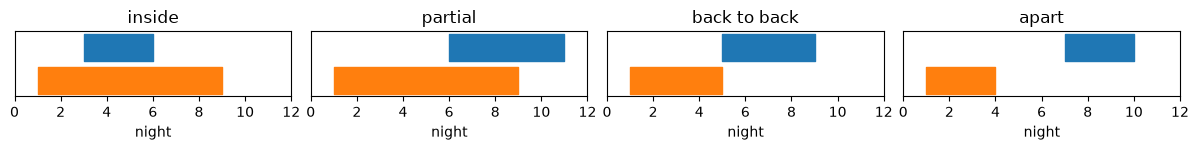

In [59]:
show_bookings(((1, 9), (3, 6), "inside"), ((1, 9), (6, 11), "partial"),
              ((1, 5), (5, 9), "back to back"), ((1, 4), (7, 10), "apart"))

"Inside" and "partial" overlap; "back to back" (one guest leaves the morning the next arrives) and "apart" do not. Moving the second booking (the upper bar) a little within the same picture would not create a new case: it is equivalent. Next, code that **might** compute the overlap, checked with plain `assert` statements on one case per class.

In [60]:
def overlap_nights(booking1, booking2):
    start = max(booking1[0], booking2[0])
    end = min(booking1[1], booking2[1])
    return end - start


assert overlap_nights((1, 9), (3, 6)) == 3        # inside
assert overlap_nights((1, 9), (6, 11)) == 3       # partial
assert overlap_nights((1, 5), (5, 9)) == 0        # back to back
print("three cases pass")

three cases pass


**Predict before running:** what does the function return for the bookings that are apart?

In [61]:
try:
    assert overlap_nights((1, 4), (7, 10)) == 0   # apart
except AssertionError:
    print("AssertionError: got", overlap_nights((1, 4), (7, 10)))

AssertionError: got -3


When the bookings are apart, `end - start` is negative. (In the original two-dimensional version, both width and height become negative and their product is *positive*, which is even harder to spot.) The fix clips the overlap at zero; afterwards we rerun *all* the cases, to check the fix broke nothing else.

In [62]:
def overlap_nights(booking1, booking2):
    start = max(booking1[0], booking2[0])
    end = min(booking1[1], booking2[1])
    return max(0, end - start)


cases = [((1, 9), (3, 6), 3), ((1, 9), (6, 11), 3), ((1, 5), (5, 9), 0), ((1, 4), (7, 10), 0),
         ((1, 9), (1, 9), 8), ((3, 6), (1, 9), 3)]
for b1, b2, expected in cases:
    assert overlap_nights(b1, b2) == expected, (b1, b2)
print(len(cases), "cases pass")

6 cases pass


**Boundary cases** deserve special attention: the limit between two classes (back to back bookings), indices at `0`, `N` and `N + 1`, an empty list, a DataFrame with one row or one column. Tests are **positive** (correct answers for valid input) and **negative** (sensible behaviour, usually a clear exception, for invalid input such as a check-out before the check-in). Bad input should fail early and explicitly, and tests check that it does.

### Comparing floats in tests

Floating-point numbers are not real numbers: `1000 * (a - b)` and `1000 * a - 1000 * b` can differ in the last digits. A test that compares floats with `==` may fail for reasons that have nothing to do with the code. `pytest.approx` compares with a relative tolerance (by default one millionth); `numpy.testing.assert_allclose` does the same for whole arrays, comparing the difference with `atol + rtol * abs(expected)`.

*Adapted from [Testing frameworks](https://github.com/alan-turing-institute/rse-course/blob/main/module05_testing_your_code/05_02_testing_frameworks.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/13-testing-frameworks.ipynb](extras/13-testing-frameworks.ipynb).*

In [63]:
import numpy as np
import pytest
from numpy.testing import assert_allclose

print(1000.0 * 1.0 - 1000.0 * 0.9999999999999998, 1000.0 * (1.0 - 0.9999999999999998))
print(0.1 + 0.2 == 0.3, 0.1 + 0.2 == pytest.approx(0.3))
assert 0.7 == pytest.approx(0.701, rel=0.1, abs=0.1)

expected = np.array([0.1, 0.2, 0.3, 0.4, 1e-12]) * np.pi
actual = np.array([0.1, 0.2, 0.3, 0.4, 2e-12]) * np.pi
actual[:-1] += 1e-6
assert_allclose(actual, expected, rtol=1e-5, atol=1e-8)
print("arrays are close")

2.2737367544323206e-13 2.220446049250313e-13
False True
arrays are close


Both printed differences should be `2e-13`; neither is. `pytest.raises` also works directly in a notebook cell, without a test file, which is handy for a quick check of a negative test.

In [64]:
with pytest.raises(ValidationError, match="must be above 0"):
    parse_price("$0.00")
print("parse_price refuses a zero price")

parse_price refuses a zero price


### More pytest: `tmp_path`, markers, selecting tests, `conftest.py`

| Feature | What it does |
|---|---|
| `tmp_path` | a built-in fixture: a fresh temporary folder for one test, for code that reads or writes files |
| `conftest.py` | fixtures defined here are available to every test file in the folder |
| `@pytest.mark.skip(reason=...)` | do not run the test (the workspace uses it for exercises) |
| `@pytest.mark.xfail` | the test is expected to fail (a known bug); it is reported, not counted as a failure |
| `pytest -k price` | run only tests whose name contains "price" |
| `pytest -x` | stop at the first failure |
| `pytest -v` | one line per test, with its name |
| `pytest --cov` | coverage report (needs the plugin `pytest-cov`, not in the course environment) |

Next, a second test folder with a `conftest.py`, a test that uses `tmp_path`, a skipped and an expected-to-fail test.

In [65]:
demo2 = Path(tempfile.mkdtemp(prefix="pytest-demo2-"))
(demo2 / "conftest.py").write_text(
    "import pytest\n\n\n"
    "@pytest.fixture\n"
    "def tiny_csv(tmp_path):\n"
    "    path = tmp_path / 'listings.csv'\n"
    "    path.write_text('id,price\\n1,80\\n2,120\\n')\n"
    "    return path\n"
)
print(sorted(p.name for p in demo2.iterdir()))

['conftest.py']


In [66]:
%%writefile {demo2}/test_files.py
import pandas as pd
import pytest


def test_reads_csv(tiny_csv):
    assert pd.read_csv(tiny_csv)["price"].median() == 100


@pytest.mark.skip(reason="exercise: delete this line when done")
def test_exercise():
    assert False


@pytest.mark.xfail(reason="known gap: the median of an empty column is NaN, not 0")
def test_known_gap():
    assert pd.Series([], dtype=float).median() == 0

Writing /var/folders/_2/pj2r648n4696ddzb0qltgpdr0000gn/T/pytest-demo2-zjzj_edf/test_files.py


In [67]:
run_pytest(demo2, "-v")

============================= test session starts ==============================
collecting ... collected 3 items

test_files.py::test_reads_csv PASSED                                     [ 33%]
test_files.py::test_exercise SKIPPED (exercise: delete this line whe...) [ 66%]
test_files.py::test_known_gap XFAIL (known gap: the median of an emp...) [100%]

=================== 1 passed, 1 skipped, 1 xfailed in 0.27s ====================


In [68]:
run_pytest(demo2, "-k", "csv")

.                                                                        [100%]
1 passed, 2 deselected in 0.26s


### Test-driven development

Writing the test first, watching it fail, then making it pass is called **test-driven development** (TDD). The cycle has three steps, often called red, green, refactor:

```mermaid
stateDiagram-v2
  [*] --> Red: write a test that fails
  Red --> Green: write the simplest code that passes
  Green --> Refactor: clean up, tests stay green
  Refactor --> Red: next behaviour
```

In its strict form, TDD means: always write and commit the tests before the code, and always cover every line. A more pragmatic reading, which this course follows:

- write tests at the same time as the production code;
- let tests shape the design: if a unit test is too hard to write, split the code into smaller, testable functions;
- when you are stuck, break the problem into smaller, testable steps;
- make sure the tests cover the core function and any checks of the input.

*Adapted from [How to test](https://github.com/alan-turing-institute/rse-course/blob/main/module05_testing_your_code/05_01_how_to_test.ipynb) (The Alan Turing Institute, *Research Software Engineering with Python*, CC BY 3.0); local copy: [extras/12-how-to-test.ipynb](extras/12-how-to-test.ipynb).*

> 📖 **Read more:** [extras/11-testing-introduction.ipynb](extras/11-testing-introduction.ipynb), [extras/12-how-to-test.ipynb](extras/12-how-to-test.ipynb) and [extras/13-testing-frameworks.ipynb](extras/13-testing-frameworks.ipynb) (Turing RSE course): the original overlapping-fields example with figures, test frameworks in other languages, coverage reports.

## Worked example · Does every Berlin listing pass the rules of `ListingRecord`?

The [workspace](../workspace/README.md) contains `ListingRecord` in [`src/listingtools/records.py`](../workspace/src/listingtools/records.py), a dataclass that combines everything above. Its `__post_init__` turns a price written as text into a number, checks that the coordinates lie inside Berlin's bounding box, accepts only the four Airbnb room types, and requires at least one guest and one night. `from_dict` builds a record from a row of the raw file.

### Step 1 · One record from a raw row

Next we import it from the workspace. `sys.path.insert` tells Python where the package lives (inside the workspace, `uv run` does this for you); `sys.dont_write_bytecode = True` stops Python from writing cache files into the repository.

In [69]:
sys.dont_write_bytecode = True
sys.path.insert(0, "sessions/02-software-engineering/workspace/src")
from listingtools import ListingRecord, ValidationError

raw = {"id": "3176", "name": " Fabulous  Flat ", "neighbourhood_group_cleansed": "Pankow",
       "latitude": "52.53574", "longitude": 13.41734, "room_type": "entire home/apt",
       "accommodates": 2, "price": "$1,160.50", "minimum_nights": "2"}
record = ListingRecord.from_dict(raw)
print(record)
print(record.price_per_guest, record.is_short_stay)

ListingRecord(id=3176, name='Fabulous Flat', district='Pankow', latitude=52.53574, longitude=13.41734, room_type='Entire home/apt', accommodates=2, price=1160.5, minimum_nights=2, maximum_nights=None)
580.25 True


### Step 2 · A record outside Berlin

A listing in Munich is refused, with the field and the reason.

In [70]:
try:
    ListingRecord.from_dict({**raw, "latitude": 48.137})
except ValidationError as err:
    print(err.field, "|", err)

latitude | latitude: 48.137 lies outside Berlin (52.33 to 52.68)


### Step 3 · Check all listings

Now all listings. `listings.to_dict("records")` turns each row into a dictionary; `Counter` counts the refused rows per field.

**Why this step?** Why does `check_all` count the refusals per field instead of stopping at the first refused row?

**Predict before running:** how many of the 10,221 listings are refused?

In [71]:
from collections import Counter


def check_all(rows):
    """Count the rows that ListingRecord refuses, per field; keep one message per field."""
    refused, example = Counter(), {}
    for row in rows:
        try:
            ListingRecord.from_dict(row)
        except ValidationError as err:
            refused[err.field] += 1
            example.setdefault(err.field, str(err))
    return refused, example


refused, example = check_all(listings.to_dict("records"))
print(refused)
print(example)

Counter({'price': 3467, 'minimum_nights': 1})
{'price': 'price: expected a finite number, got nan', 'minimum_nights': 'minimum_nights: expected a whole number, got nan'}


### Step 4 · `NaN` against `None` at the boundary

**Why this step?** Why convert `NaN` to `None` where the data enter the program, and not inside `ListingRecord`?

Most refusals concern the price. pandas writes a missing price as `NaN`, a float, not as `None`. `ListingRecord` accepts `None` ("no price") but refuses `NaN`, because `NaN` would silently spread into every average. The decision belongs at the boundary where data enter the program: we convert `NaN` to `None` before building records. `.where(listings.notna(), None)` replaces every missing value by `None`.

In [72]:
as_python = listings.astype(object).where(listings.notna(), None)
refused, example = check_all(as_python.to_dict("records"))
print(refused)
print(example)

Counter({'minimum_nights': 2})
{'minimum_nights': 'minimum_nights: expected a whole number, got None'}


What remains are listings without a minimum stay. Whether they should be dropped, or whether `minimum_nights` should default to 1, is a decision for the team, written down as a rule and a test. Exercise 1.6 continues this class in the workspace.

## Check your understanding

Vote alone, discuss with your neighbour, vote again.

1. `flat = Listing(3176, "Pankow", 160.71, 2)`, then `flat.price_per_guest()`. What is `self` inside `price_per_guest`?
   - A. The class `Listing`
   - B. A copy of `flat`, made for this call
   - C. The object `flat` itself
   - D. The first argument after the object, `3176`
2. `ListingTable` holds a pandas DataFrame as an attribute. Which relation is that?
   - A. Composition: a `ListingTable` *has* a DataFrame
   - B. Inheritance: a `ListingTable` *is* a DataFrame
   - C. Polymorphism, because both classes have methods
   - D. Neither: an attribute cannot hold another object
3. What does `@dataclass` write for you, and where do the checks of the fields go?
   - A. Only `__repr__`; the checks go into an `__init__` that you write yourself
   - B. `__init__`, `__repr__` and `__eq__`; the checks go into a method that every caller must remember to call
   - C. Nothing that runs: it is a hint for type checkers
   - D. `__init__`, `__repr__` and `__eq__`; the checks go into `__post_init__`, which runs right after the generated `__init__`
4. A function has the hint `price: float` and is called with the text `"$85.00"`. What happens?
   - A. A `TypeError` at the call
   - B. Python converts the text to `85.0`
   - C. The call runs; it fails later, or gives a wrong result, where the text is used in arithmetic
   - D. mypy stops the program while it runs
5. Why does `ValidationError` inherit from both `ListingToolsError` and `ValueError`?
   - A. Python requires an exception class to have two parents
   - B. So that callers can catch every error of the package with `ListingToolsError`, and code that already catches `ValueError` keeps working
   - C. So that the error is raised twice, once for each parent
   - D. Because a `ValueError` alone cannot carry a message

## Exercises

Work in pairs. The lecturer chooses which exercises to set; there are more than fit into the time in class, and *Stretch* tasks are for pairs that finish early. Tests can be plain functions with `assert` that you call yourself, or a test file written with `%%writefile` and run with `run_pytest` as in the section on automated tests. Exercise 1.6 is solved in the files of the [workspace](../workspace/README.md) (`cd sessions/02-software-engineering/workspace`, then `uv run pytest -q`).

### 1.1 · Rock, paper, scissors

*Code*

> Write a function `winner(a, b)` that takes the moves of two players (`"rock"`, `"paper"` or
> `"scissors"`) and returns `"a"`, `"b"` or `"draw"`. Then write three tests. What should happen for `"lizard"`?

*Source:* [Rock paper scissors, Wikipedia](https://en.wikipedia.org/wiki/Rock_paper_scissors)

### 1.2 · Break your neighbour's password checker

*Pairs*

> Write `check_password(pw)` that returns a list of problems (an empty list means the password is
> accepted). Choose your own rules. Then swap laptops: write test cases that your neighbour's checker gets *wrong*,
> either a weak password it accepts or a good one it refuses. The pair with the most successful attacks wins.

*Source:* [NIST SP 800-63B (rev. 4), password requirements](https://pages.nist.gov/800-63-4/sp800-63b.html)

### 1.3 · A shopping cart

*Code*

> Write a class `Cart` with `add(name, price, quantity=1)`, `remove(name)`, `total()` and
> `apply_code(code)`. The code `"STUDENT10"` gives 10 % off; an unknown code raises `ValueError`; removing an item
> that is not in the cart raises `KeyError`. Create two carts, add items to one of them and print both totals.

*Source:* original exercise for this course; background: [Python tutorial: Classes](https://docs.python.org/3/tutorial/classes.html)

### 1.4 · A bank account that says no

*Code*

> Write a class `Account` with `deposit(amount)` and `withdraw(amount)`. A withdrawal that would make
> the balance negative raises your own exception `InsufficientFunds`; a deposit of zero or less raises `ValueError`.
> Write the tests *first*, then the class.

*Source:* original exercise for this course; background: [Python tutorial: User-defined exceptions](https://docs.python.org/3/tutorial/errors.html#user-defined-exceptions)

### 1.5 · Animals that speak

*Code, then Class*

> Write a class `Animal` with a `name` and a method `speak()`. Write subclasses `Dog`, `Cat` and `Duck`
> that each say something different. Put one of each in a list and let them all speak in one loop. Then add a `Puppy`
> that speaks like a dog but adds "(tiny)".

*Source:* [Python tutorial: Inheritance](https://docs.python.org/3/tutorial/classes.html#inheritance); [Liskov substitution principle, Wikipedia](https://en.wikipedia.org/wiki/Liskov_substitution_principle)

### 1.6 · A listing that validates itself (workspace)

*Pairs*

> In the workspace, open `src/listingtools/records.py` and `tests/test_records.py`.
>
> 1. Complete the TODO in `ListingRecord.__post_init__`: `maximum_nights` is optional (`None` stays `None`); the raw file writes 2,147,483,647 when a host set no limit, which also becomes `None`; otherwise it is converted with `parse_int` and must not be smaller than `minimum_nights`. Delete the two `skip` lines of `test_maximum_nights_rules` and `test_maximum_nights_rejects_invalid_values` and run `uv run pytest -q tests/test_records.py`.
> 2. Add tests for two rules that are not tested yet: the room type `"  private ROOM "` becomes `"Private room"`, and `minimum_nights=0` is rejected. Write each test first, run it, and check that it would fail if the rule were wrong (change the expected value once).

*Source:* original exercise for this course (workspace exercises 1 and 2); data shaped like the Inside Airbnb Berlin file (CC BY 4.0).

*Your answer:*

### 1.7 · *Stretch:* Fractions that add up

*Code*

> In Session 1 we saw `0.1 + 0.2 != 0.3`. Write a class `Fraction` so that
> `Fraction(1, 10) + Fraction(2, 10) == Fraction(3, 10)` is `True` and `print(Fraction(2, 4))` shows `1/2`.

*Source:* [Python docs: `fractions`](https://docs.python.org/3/library/fractions.html); [Python reference: emulating numeric types](https://docs.python.org/3/reference/datamodel.html#emulating-numeric-types)

### 1.8 · *Stretch:* A deck of cards

*Code*

> Write a class `Card` (rank and suit, printed as `"Q♥"`) and a class `Deck` that creates all 52 cards,
> can `shuffle()` and can `deal(n)` cards. Then estimate by simulation: how often does a hand of 5 cards contain
> exactly one pair? Guess first.

*Source:* [Downey, *Think Python* (2nd ed.), chapter 18: Inheritance (cards and decks)](https://greenteapress.com/thinkpython2/html/thinkpython2019.html); [Poker probability, Wikipedia](https://en.wikipedia.org/wiki/Poker_probability)

### 1.9 · A parametrized test, in the right order

*Parsons*

> The lines below form a test file for the corrected `overlap_nights` of *Choosing test cases: equivalence classes and boundaries*, which lives in a module `bookings.py`. They are shuffled, and the indentation is kept. Put them in order so that `pytest` runs one test per pair of bookings, then say how many tests it reports.
>
> ```python
>     assert overlap_nights(booking1, booking2) == expected
> ])
> import pytest
> def test_overlap_nights(booking1, booking2, expected):
>     ((1, 9), (3, 6), 3), ((1, 5), (5, 9), 0), ((1, 4), (7, 10), 0),
> from bookings import overlap_nights
> @pytest.mark.parametrize(("booking1", "booking2", "expected"), [
> ```

*Source:* original exercise for this course, on the bookings example of the Turing RSE course.

*Your answer:*

### 1.10 · A price parser that never fails

*Find the bug*

> Both `assert` lines pass, and the function never raises an error. Find an input for which it returns a wrong number without any warning, explain which line hides the problem, and write the test that would have caught it. Then fix the function.
>
> ```python
> def price_from_text(text):
>     """Turn a price such as "$1,083.00" into a float."""
>     try:
>         return float(text.replace("$", "").replace(",", ""))
>     except Exception:
>         return 0.0
>
>
> assert price_from_text("$85.00") == 85.0
> assert price_from_text("$1,083.00") == 1083.0
> ```

*Source:* original exercise for this course, after *Why a bare `except:` is dangerous*.

*Your answer:*

## Debrief

- **Rules as data.** Compare a `winner` written as nine `if` branches with one that looks up "what beats what" in a dictionary. Which one is easier to extend to "lizard" and "Spock"? Connect it to the refactoring to polymorphism in the section on composition and inheritance.
- **Typical mistake: shared state.** In the cart, look for `items` defined on the class instead of in `__init__`: the second customer then pays for the first one's shopping (the `Wishlist` bug of the subsection on class attributes).
- **The test nobody writes.** In the bank account, ask which test checks that the balance is unchanged after a refused withdrawal.
- **Passwords.** Which attacks worked? Compare the pairs' rules with what NIST SP 800-63B recommends.
- **A failure that hides (1.10).** Which input did each pair find, and does their new test use `pytest.raises`?
- **Bridge to block 2.** The classes and tests now live in cells of one notebook. Block 2 moves such code into a package that others can import, keeps its history in Git, and lets GitHub run the tests on every change.

## Further reading

- The Alan Turing Institute. *Research Software Engineering with Python*, modules 2 (defining classes), 5 (testing), 6 (documentation), 7 (construction and design) and 8 (exceptions). CC BY 3.0. https://alan-turing-institute.github.io/rse-course/ (extras 05–13 of this session).
- Downey, A. B. (2024). *Think Python*, 3rd edition, chapters 14–17. Free online, CC BY-NC-SA 4.0. https://allendowney.github.io/ThinkPython/ (extras 01–04).
- VanderPlas, J. (2016). *A Whirlwind Tour of Python*, "Errors and Exceptions". CC0. In [Session 1, extras/07](../../01-careers-and-python/workbooks/extras/07-python-errors-and-exceptions.ipynb).
- The Carpentries Incubator (2024). *Intermediate Research Software Development in Python*, sections on testing and software design. CC BY 4.0. https://carpentries-incubator.github.io/python-intermediate-development/
- Python Software Foundation (2026). *dataclasses: Data Classes*; *typing: Support for type hints*. https://docs.python.org/3/library/dataclasses.html, https://docs.python.org/3/library/typing.html
- pytest developers (2026). *Get started* and *How to parametrize fixtures and test functions*. https://docs.pytest.org/en/stable/getting-started.html
- Lehtosalo, J. et al. (2019). *Our journey to type checking 4 million lines of Python*. Dropbox Tech Blog. https://dropbox.tech/application/our-journey-to-type-checking-4-million-lines-of-python
- BBC News (2020, 5 October). *Covid: Test error should never have happened, Hancock*. https://www.bbc.com/news/uk-54422505
- Herndon, T., Ash, M., & Pollin, R. (2014). Does high public debt consistently stifle economic growth? A critique of Reinhart and Rogoff. *Cambridge Journal of Economics*, 38(2), 257–279. https://doi.org/10.1093/cje/bet075
- Inside Airbnb (2026). *Berlin, 26 June 2026 snapshot*. CC BY 4.0. https://insideairbnb.com/get-the-data/

Provenance of all extras: [extras/README.md](extras/README.md).